<a href="https://colab.research.google.com/github/josecano8910/tavns-mindfulness-hrv-pipeline/blob/main/analysis/hrv_2x2_anova.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [5]:

import numpy as np
import pandas as pd
from scipy import signal, interpolate
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from statsmodels.formula.api import ols

np.random.seed(42)

# 1. Kubios-style RR-interval artifact detection & interpolation
def clean_rr_and_compute_hrv(rr_ms, threshold_pct=0.20, fs_interp=4.0):
    rr = np.asarray(rr_ms, dtype=float)
    local_med = pd.Series(rr).rolling(window=5, center=True, min_periods=1).median().to_numpy()
    artifacts = (rr < 300) | (rr > 2000) | (np.abs(rr - local_med) > (threshold_pct * local_med))
    pct_corrected = (np.sum(artifacts) / len(rr)) * 100.0

    if np.any(artifacts):
        valid_idx = np.where(~artifacts)[0]
        rr_clean = np.interp(np.arange(len(rr)), valid_idx, rr[valid_idx])
    else:
        rr_clean = rr.copy()

    diffs = np.diff(rr_clean)
    rmssd = np.sqrt(np.mean(diffs ** 2))
    sdnn = np.std(rr_clean, ddof=1)
    pnn50 = (np.sum(np.abs(diffs) > 50.0) / len(diffs)) * 100.0

    # Frequency-domain LF/HF via cubic spline resampling + Welch PSD
    t_beats = np.cumsum(rr_clean) / 1000.0
    t_beats = t_beats - t_beats[0]
    t_uniform = np.arange(0, t_beats[-1], 1.0 / fs_interp)
    cs = interpolate.CubicSpline(t_beats, rr_clean)
    freqs, psd = signal.welch(signal.detrend(cs(t_uniform)), fs=fs_interp, nperseg=min(256, len(t_uniform)))

    lf_mask = (freqs >= 0.04) & (freqs < 0.15)
    hf_mask = (freqs >= 0.15) & (freqs <= 0.40)
    lf = np.trapezoid(psd[lf_mask], freqs[lf_mask])
    hf = np.trapezoid(psd[hf_mask], freqs[hf_mask])

    return round(rmssd, 2), round(sdnn, 2), round(pnn50, 2), round(lf / hf, 2), round(pct_corrected, 2)

# 2. Simulate N=40 cohort across the 2x2 factorial design (10 per cell)
conditions = [
    ("C1_Active_Mindful", "Active", "Mindfulness", 13.0, -48),
    ("C2_Active_NoMind",  "Active", "No_Mindfulness", 6.8, -22),
    ("C3_Sham_Mindful",   "Sham",   "Mindfulness", 6.0, -19),
    ("C4_Sham_NoMind",    "Sham",   "No_Mindfulness", 0.5, -3)
]

rows = []
sub_id_num = 1
for cond_id, stim, mind, rmssd_shift, rt_shift in conditions:
    for _ in range(10):
        base_rr = np.random.normal(810, 32, size=150)
        base_rr[15] = 1480.0  # Inject synthetic artifact at beat 15 to test filter

        post_rr = np.random.normal(810 + (rmssd_shift * 2.2), 32 + (rmssd_shift * 0.8), size=150)

        b_rmssd, b_sdnn, b_pnn50, b_lfhf, b_art = clean_rr_and_compute_hrv(base_rr)
        p_rmssd, p_sdnn, p_pnn50, p_lfhf, p_art = clean_rr_and_compute_hrv(post_rr)

        base_rt = np.random.normal(545.0, 42.0)
        post_rt = base_rt + np.random.normal(rt_shift, 16.0)

        rows.append([
            f"sub-{sub_id_num:02d}", cond_id, stim, mind,
            b_rmssd, p_rmssd, round(p_rmssd - b_rmssd, 2),
            p_sdnn, p_pnn50, p_lfhf, b_art,
            round(base_rt, 1), round(post_rt, 1), round(post_rt - base_rt, 1)
        ])
        sub_id_num += 1

cols = [
    "participant", "condition", "stimulation", "mindfulness",
    "baseline_rmssd_ms", "post_rmssd_ms", "rmssd_change_ms",
    "post_sdnn_ms", "post_pnn50_pct", "post_lf_hf_ratio", "baseline_artifacts_pct",
    "baseline_rt_ms", "post_rt_ms", "rt_change_ms"
]

df = pd.DataFrame(rows, columns=cols)
df.to_csv("synthetic_2x2_hrv.csv", index=False)
print(f"Dataset ready: {len(df)} participants across 4 conditions.")
df.head()

Dataset ready: 40 participants across 4 conditions.


,participant,condition,stimulation,mindfulness,baseline_rmssd_ms,post_rmssd_ms,rmssd_change_ms,post_sdnn_ms,post_pnn50_pct,post_lf_hf_ratio,baseline_artifacts_pct,baseline_rt_ms,post_rt_ms,rt_change_ms
0,sub-01,C1_Active_Mindful,Active,Mindfulness,44.16,63.93,19.77,43.32,42.28,0.31,0.67,510.2,453.2,-57.0
1,sub-02,C1_Active_Mindful,Active,Mindfulness,41.04,56.93,15.89,41.20,39.60,0.57,0.67,581.5,555.2,-26.3
2,sub-03,C1_Active_Mindful,Active,Mindfulness,47.92,55.66,7.74,39.55,39.60,0.55,0.67,553.0,505.8,-47.3
3,sub-04,C1_Active_Mindful,Active,Mindfulness,43.28,62.57,19.29,44.23,40.27,0.28,0.67,515.5,456.9,-58.6
4,sub-05,C1_Active_Mindful,Active,Mindfulness,44.69,59.28,14.59,42.00,38.93,0.54,0.67,548.7,524.4,-24.4


In [8]:

# Automated Quality Control Check (Exclude if baseline artifacts > 5%)
clean_df = df[df["baseline_artifacts_pct"] <= 5.0].copy()
print(f"QC Audit: Retained {len(clean_df)}/{len(df)} participants (<= 5% interpolated beats).\n")

# Run 2x2 ANOVA on Vagal Tone Change (Delta RMSSD)
model = ols("rmssd_change_ms ~ C(stimulation) * C(mindfulness)", data=clean_df).fit()
anova_table = sm.stats.anova_lm(model, typ=2)
print("=== 2x2 Factorial ANOVA: Δ RMSSD (Post - Baseline) ===")
print(anova_table.round(4))

QC Audit: Retained 40/40 participants (<= 5% interpolated beats).

=== 2x2 Factorial ANOVA: Δ RMSSD (Post - Baseline) ===
                                 sum_sq    df        F  PR(>F)
C(stimulation)                 355.8122   1.0  13.1986  0.0009
C(mindfulness)                 217.3424   1.0   8.0622  0.0074
C(stimulation):C(mindfulness)    4.7748   1.0   0.1771  0.6764
Residual                       970.4967  36.0      NaN     NaN


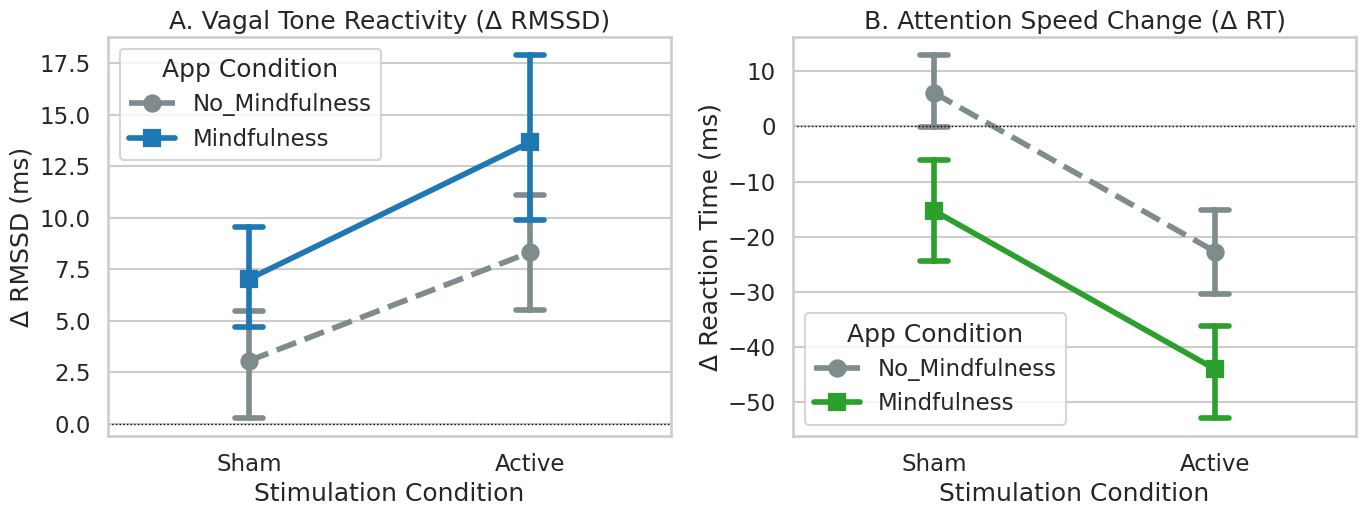

In [10]:

sns.set_theme(style="whitegrid", context="talk")
fig, (ax_left, ax_right) = plt.subplots(1, 2, figsize=(14, 5.5))

# Panel A: Vagal Tone (RMSSD Change)
sns.pointplot(
    data=clean_df, x="stimulation", y="rmssd_change_ms", hue="mindfulness",
    order=["Sham", "Active"], hue_order=["No_Mindfulness", "Mindfulness"],
    palette=["#7f8c8d", "#1f77b4"], markers=["o", "s"], linestyles=["--", "-"],
    capsize=0.1, ax=ax_left
)
ax_left.axhline(0, color="black", linestyle=":", linewidth=1)
ax_left.set_title("A. Vagal Tone Reactivity (Δ RMSSD)")
ax_left.set_xlabel("Stimulation Condition")
ax_left.set_ylabel("Δ RMSSD (ms)")
ax_left.legend(title="App Condition")

# Panel B: Cognitive Speed (RT Change)
sns.pointplot(
    data=clean_df, x="stimulation", y="rt_change_ms", hue="mindfulness",
    order=["Sham", "Active"], hue_order=["No_Mindfulness", "Mindfulness"],
    palette=["#7f8c8d", "#2ca02c"], markers=["o", "s"], linestyles=["--", "-"],
    capsize=0.1, ax=ax_right
)
ax_right.axhline(0, color="black", linestyle=":", linewidth=1)
ax_right.set_title("B. Attention Speed Change (Δ RT)")
ax_right.set_xlabel("Stimulation Condition")
ax_right.set_ylabel("Δ Reaction Time (ms)")
ax_right.legend(title="App Condition")

plt.tight_layout()
plt.savefig("tavns_mindfulness_2x2_results.png", dpi=300)
plt.show()